# healthcare-policy-iteration

**Read first:** Sutton and Barto, Chapter 4. This lab applies policy evaluation, policy improvement, policy iteration, and value iteration to configurable rectangular Gridworlds. The default is Example 4.1; the explanations and proofs remain in the chapter.

Source: Sutton and Barto, *Reinforcement Learning: An Introduction*, 2nd ed., [Chapter 4](http://incompleteideas.net/book/RLbook2020.pdf), 

In [25]:
from typing import Final, Literal, TypeAlias, TypeVar

import numpy as np
import numpy.typing as npt
import matplotlib.pyplot as plt
from matplotlib.axes import Axes
from matplotlib.figure import Figure
from IPython.display import HTML
from pygments import highlight
from pygments.formatters import HtmlFormatter
from pygments.lexers import get_lexer_by_name  # pyright: ignore[reportUnknownVariableType]
import IPython.display as notebook_display
from sqlalchemy import (
    Boolean, Float, ForeignKey, Integer, String, case, create_engine,
    func, insert, literal, select,
)
from sqlalchemy.orm import DeclarativeBase, Mapped, Session, aliased, mapped_column
from sqlalchemy.pool import StaticPool

FloatArray: TypeAlias = npt.NDArray[np.float64]
Algorithm: TypeAlias = Literal[
    "exact_evaluation", "iterative_evaluation", "policy_improvement",
    "policy_iteration", "value_iteration", "truncated_iteration", "distance_reference",
]
ValueKind: TypeAlias = Literal[
    "initial", "policy_estimate", "policy_exact", "optimal_estimate", "optimal_exact",
]

## 1. Data model

We use a SQL schema to represent the full data model for computing policy evaluation and policy improvement in the healthcare MDP. The schema stores the states, actions, transitions, rewards, policies, and experiment results used throughout the notebook.

In [26]:
SCHEMA_SQL: Final[str] = """\
PRAGMA foreign_keys = ON;

CREATE TABLE world (
    id INTEGER PRIMARY KEY,
    name TEXT NOT NULL UNIQUE,
    discount REAL NOT NULL CHECK (discount > 0.0 AND discount <= 1.0)
);

CREATE TABLE state (
    id INTEGER PRIMARY KEY,
    world_id INTEGER NOT NULL REFERENCES world(id),
    name TEXT NOT NULL,
    ordinal INTEGER NOT NULL CHECK (ordinal >= 0),
    is_terminal INTEGER NOT NULL CHECK (is_terminal IN (0, 1)),
    UNIQUE (world_id, id),
    UNIQUE (world_id, name),
    UNIQUE (world_id, ordinal)
);

CREATE UNIQUE INDEX one_terminal_state_per_world
ON state(world_id) WHERE is_terminal = 1;

CREATE TABLE action (
    id INTEGER PRIMARY KEY,
    name TEXT NOT NULL UNIQUE
);

CREATE TABLE transition (
    world_id INTEGER NOT NULL REFERENCES world(id),
    state_id INTEGER NOT NULL,
    action_id INTEGER NOT NULL REFERENCES action(id),
    next_state_id INTEGER NOT NULL,
    reward REAL NOT NULL,
    PRIMARY KEY (state_id, action_id),
    FOREIGN KEY (world_id, state_id) REFERENCES state(world_id, id),
    FOREIGN KEY (world_id, next_state_id) REFERENCES state(world_id, id)
);

CREATE TABLE policy (
    id INTEGER PRIMARY KEY,
    world_id INTEGER NOT NULL REFERENCES world(id),
    name TEXT NOT NULL,
    tie_strategy TEXT NOT NULL CHECK (tie_strategy IN ('uniform', 'first', 'given')),
    origin_snapshot_id INTEGER,
    UNIQUE (world_id, id),
    FOREIGN KEY (world_id, origin_snapshot_id) REFERENCES snapshot(world_id, id)
);

CREATE TABLE policy_probability (
    world_id INTEGER NOT NULL REFERENCES world(id),
    policy_id INTEGER NOT NULL,
    state_id INTEGER NOT NULL,
    action_id INTEGER NOT NULL REFERENCES action(id),
    probability REAL NOT NULL CHECK (probability BETWEEN 0.0 AND 1.0),
    PRIMARY KEY (policy_id, state_id, action_id),
    FOREIGN KEY (world_id, policy_id) REFERENCES policy(world_id, id),
    FOREIGN KEY (world_id, state_id) REFERENCES state(world_id, id)
);

CREATE TABLE run (
    id INTEGER PRIMARY KEY,
    world_id INTEGER NOT NULL REFERENCES world(id),
    name TEXT NOT NULL,
    algorithm TEXT NOT NULL CHECK (algorithm IN (
        'exact_evaluation', 'iterative_evaluation', 'policy_improvement',
        'policy_iteration', 'value_iteration', 'truncated_iteration'
    )),
    tolerance REAL NOT NULL CHECK (tolerance > 0.0),
    tie_tolerance REAL NOT NULL CHECK (tie_tolerance >= 0.0),
    max_iterations INTEGER NOT NULL CHECK (max_iterations > 0),
    evaluation_sweeps INTEGER NOT NULL CHECK (evaluation_sweeps > 0),
    iterations INTEGER NOT NULL DEFAULT 0 CHECK (iterations >= 0),
    completed_sweeps INTEGER NOT NULL DEFAULT 0 CHECK (completed_sweeps >= 0),
    status TEXT NOT NULL CHECK (status IN ('running', 'converged', 'failed')),
    initial_policy_id INTEGER,
    current_policy_id INTEGER,
    latest_snapshot_id INTEGER,
    reference_snapshot_id INTEGER,
    UNIQUE (world_id, id),
    UNIQUE (world_id, name),
    FOREIGN KEY (world_id, initial_policy_id) REFERENCES policy(world_id, id),
    FOREIGN KEY (world_id, current_policy_id) REFERENCES policy(world_id, id),
    FOREIGN KEY (world_id, latest_snapshot_id) REFERENCES snapshot(world_id, id),
    FOREIGN KEY (world_id, reference_snapshot_id) REFERENCES snapshot(world_id, id)
);

CREATE TABLE snapshot (
    id INTEGER PRIMARY KEY,
    world_id INTEGER NOT NULL REFERENCES world(id),
    run_id INTEGER NOT NULL,
    sequence INTEGER NOT NULL CHECK (sequence >= 0),
    completed_sweeps INTEGER NOT NULL CHECK (completed_sweeps >= 0),
    value_kind TEXT NOT NULL CHECK (value_kind IN (
        'initial', 'policy_estimate', 'policy_exact', 'optimal_estimate', 'optimal_exact'
    )),
    target_policy_id INTEGER,
    greedy_policy_id INTEGER,
    policy_residual REAL CHECK (policy_residual >= 0.0),
    optimality_residual REAL CHECK (optimality_residual >= 0.0),
    changed_policy_states INTEGER CHECK (changed_policy_states >= 0),
    UNIQUE (world_id, id),
    UNIQUE (run_id, sequence),
    FOREIGN KEY (world_id, run_id) REFERENCES run(world_id, id),
    FOREIGN KEY (world_id, target_policy_id) REFERENCES policy(world_id, id),
    FOREIGN KEY (world_id, greedy_policy_id) REFERENCES policy(world_id, id),
    CHECK (
        (value_kind IN ('policy_estimate', 'policy_exact') AND target_policy_id IS NOT NULL)
        OR value_kind IN ('initial', 'optimal_estimate', 'optimal_exact')
    )
);

CREATE TABLE state_value (
    world_id INTEGER NOT NULL REFERENCES world(id),
    snapshot_id INTEGER NOT NULL,
    state_id INTEGER NOT NULL,
    value REAL NOT NULL,
    PRIMARY KEY (snapshot_id, state_id),
    FOREIGN KEY (world_id, snapshot_id) REFERENCES snapshot(world_id, id),
    FOREIGN KEY (world_id, state_id) REFERENCES state(world_id, id)
);

CREATE TABLE action_value (
    world_id INTEGER NOT NULL REFERENCES world(id),
    snapshot_id INTEGER NOT NULL,
    state_id INTEGER NOT NULL,
    action_id INTEGER NOT NULL REFERENCES action(id),
    value REAL NOT NULL,
    PRIMARY KEY (snapshot_id, state_id, action_id),
    FOREIGN KEY (world_id, snapshot_id) REFERENCES snapshot(world_id, id),
    FOREIGN KEY (world_id, state_id) REFERENCES state(world_id, id)
);
"""

# Inline colors do not depend on classic Jupyter CSS classes or style sheets.
formatted_sql: str = highlight(
    SCHEMA_SQL,
    get_lexer_by_name("sql"),
    HtmlFormatter(noclasses=True, cssclass="", style="dracula"),
)
notebook_display.display(  # pyright: ignore[reportUnknownMemberType]
    HTML(formatted_sql)
)

In [27]:
engine = create_engine("sqlite+pysqlite:///:memory:", poolclass=StaticPool)
with engine.begin() as connection:
    for statement in SCHEMA_SQL.split(";"):
        if statement.strip():
            connection.exec_driver_sql(statement)

### One set of Python models

These ORM classes map the SQL schema to Python and represent the MDP data model used in the healthcare environment. SQL defines the tables and enforces their constraints.

In [28]:
class Base(DeclarativeBase):
    pass


_ModelT = TypeVar("_ModelT", bound=Base)


def store(db: Session, model: _ModelT) -> _ModelT:
    db.add(model)
    db.flush()
    return model


class World(Base):
    __tablename__ = "world"
    id: Mapped[int] = mapped_column(Integer, primary_key=True)
    name: Mapped[str] = mapped_column(String)
    discount: Mapped[float] = mapped_column(Float)


class State(Base):
    __tablename__ = "state"
    id: Mapped[int] = mapped_column(Integer, primary_key=True)
    world_id: Mapped[int] = mapped_column(ForeignKey("world.id"))
    name: Mapped[str] = mapped_column(String)
    ordinal: Mapped[int] = mapped_column(Integer)
    is_terminal: Mapped[bool] = mapped_column(Boolean)


class Action(Base):
    __tablename__ = "action"
    id: Mapped[int] = mapped_column(Integer, primary_key=True)
    name: Mapped[str] = mapped_column(String)


class Transition(Base):
    __tablename__ = "transition"
    world_id: Mapped[int] = mapped_column(ForeignKey("world.id"))
    state_id: Mapped[int] = mapped_column(ForeignKey("state.id"), primary_key=True)
    action_id: Mapped[int] = mapped_column(ForeignKey("action.id"), primary_key=True)
    next_state_id: Mapped[int] = mapped_column(ForeignKey("state.id"))
    reward: Mapped[float] = mapped_column(Float)


class Policy(Base):
    __tablename__ = "policy"
    id: Mapped[int] = mapped_column(Integer, primary_key=True)
    world_id: Mapped[int] = mapped_column(ForeignKey("world.id"))
    name: Mapped[str] = mapped_column(String)
    tie_strategy: Mapped[str] = mapped_column(String)
    origin_snapshot_id: Mapped[int | None] = mapped_column(ForeignKey("snapshot.id"))


class PolicyProbability(Base):
    __tablename__ = "policy_probability"
    world_id: Mapped[int] = mapped_column(ForeignKey("world.id"))
    policy_id: Mapped[int] = mapped_column(ForeignKey("policy.id"), primary_key=True)
    state_id: Mapped[int] = mapped_column(ForeignKey("state.id"), primary_key=True)
    action_id: Mapped[int] = mapped_column(ForeignKey("action.id"), primary_key=True)
    probability: Mapped[float] = mapped_column(Float)


class Run(Base):
    __tablename__ = "run"
    id: Mapped[int] = mapped_column(Integer, primary_key=True)
    world_id: Mapped[int] = mapped_column(ForeignKey("world.id"))
    name: Mapped[str] = mapped_column(String)
    algorithm: Mapped[str] = mapped_column(String)
    tolerance: Mapped[float] = mapped_column(Float)
    tie_tolerance: Mapped[float] = mapped_column(Float)
    max_iterations: Mapped[int] = mapped_column(Integer)
    evaluation_sweeps: Mapped[int] = mapped_column(Integer)
    iterations: Mapped[int] = mapped_column(Integer)
    completed_sweeps: Mapped[int] = mapped_column(Integer)
    status: Mapped[str] = mapped_column(String)
    initial_policy_id: Mapped[int | None] = mapped_column(ForeignKey("policy.id"))
    current_policy_id: Mapped[int | None] = mapped_column(ForeignKey("policy.id"))
    latest_snapshot_id: Mapped[int | None] = mapped_column(ForeignKey("snapshot.id"))
    reference_snapshot_id: Mapped[int | None] = mapped_column(ForeignKey("snapshot.id"))


class Snapshot(Base):
    __tablename__ = "snapshot"
    id: Mapped[int] = mapped_column(Integer, primary_key=True)
    world_id: Mapped[int] = mapped_column(ForeignKey("world.id"))
    run_id: Mapped[int] = mapped_column(ForeignKey("run.id"))
    sequence: Mapped[int] = mapped_column(Integer)
    completed_sweeps: Mapped[int] = mapped_column(Integer)
    value_kind: Mapped[str] = mapped_column(String)
    target_policy_id: Mapped[int | None] = mapped_column(ForeignKey("policy.id"))
    greedy_policy_id: Mapped[int | None] = mapped_column(ForeignKey("policy.id"))
    policy_residual: Mapped[float | None] = mapped_column(Float)
    optimality_residual: Mapped[float | None] = mapped_column(Float)
    changed_policy_states: Mapped[int | None] = mapped_column(Integer)


class StateValue(Base):
    __tablename__ = "state_value"
    world_id: Mapped[int] = mapped_column(ForeignKey("world.id"))
    snapshot_id: Mapped[int] = mapped_column(ForeignKey("snapshot.id"), primary_key=True)
    state_id: Mapped[int] = mapped_column(ForeignKey("state.id"), primary_key=True)
    value: Mapped[float] = mapped_column(Float)


class ActionValue(Base):
    __tablename__ = "action_value"
    world_id: Mapped[int] = mapped_column(ForeignKey("world.id"))
    snapshot_id: Mapped[int] = mapped_column(ForeignKey("snapshot.id"), primary_key=True)
    state_id: Mapped[int] = mapped_column(ForeignKey("state.id"), primary_key=True)
    action_id: Mapped[int] = mapped_column(ForeignKey("action.id"), primary_key=True)
    value: Mapped[float] = mapped_column(Float)

## 2. Create a Healthcare MDP in SQL

The constructor writes the complete healthcare environment to SQL, including the states, actions, transitions, and rewards. The environment contains four patient states—Stable, At_Risk, Critical, and Recovered—and three available actions—Monitor, Treat, and Escalate. Recovered is defined as the terminal state, and all transitions are stored and retrieved from SQL.

In [29]:
def create_world(
    db: Session,
    name: str,
) -> World:
    # Create the healthcare MDP world.
    world = store(
        db,
        World(
            name=name,
            discount=0.9,
        ),
    )

    # Create healthcare states.
    states = {
        "Stable": store(
            db,
            State(
                world_id=world.id,
                name="Stable",
                ordinal=0,
                is_terminal=False,
            ),
        ),
        "At_Risk": store(
            db,
            State(
                world_id=world.id,
                name="At_Risk",
                ordinal=1,
                is_terminal=False,
            ),
        ),
        "Critical": store(
            db,
            State(
                world_id=world.id,
                name="Critical",
                ordinal=2,
                is_terminal=False,
            ),
        ),
        "Recovered": store(
            db,
            State(
                world_id=world.id,
                name="Recovered",
                ordinal=3,
                is_terminal=True,
            ),
        ),
    }

    db.flush()

    # Load actions by name.
    actions = {
        action.name: action
        for action in db.scalars(select(Action).order_by(Action.id))
    }

    # Deterministic healthcare transitions:
    # (current_state, action, next_state, reward)
    transitions = [
        ("Stable", "Monitor", "Recovered", 10.0),
        ("Stable", "Treat", "Recovered", 7.0),
        ("Stable", "Escalate", "Recovered", 4.0),

        ("At_Risk", "Monitor", "Critical", -8.0),
        ("At_Risk", "Treat", "Stable", 5.0),
        ("At_Risk", "Escalate", "Stable", 2.0),

        ("Critical", "Monitor", "Critical", -10.0),
        ("Critical", "Treat", "At_Risk", -2.0),
        ("Critical", "Escalate", "Stable", 4.0),

        ("Recovered", "Monitor", "Recovered", 0.0),
        ("Recovered", "Treat", "Recovered", 0.0),
        ("Recovered", "Escalate", "Recovered", 0.0),
    ]

    for state_name, action_name, next_state_name, reward in transitions:
        store(
            db,
            Transition(
                world_id=world.id,
                state_id=states[state_name].id,
                action_id=actions[action_name].id,
                next_state_id=states[next_state_name].id,
                reward=reward,
            ),
        )

    db.flush()
    return world


def uniform_policy(db: Session, world: World) -> Policy:
    policy = store(
        db,
        Policy(
            world_id=world.id,
            name="uniform",
            tie_strategy="given",
        ),
    )

    action_count = db.scalar(select(func.count()).select_from(Action))
    if not action_count:
        raise ValueError("Create the actions first.")

    probability = 1.0 / action_count

    for transition in db.scalars(
        select(Transition).where(Transition.world_id == world.id)
    ):
        store(
            db,
            PolicyProbability(
                world_id=world.id,
                policy_id=policy.id,
                state_id=transition.state_id,
                action_id=transition.action_id,
                probability=probability,
            ),
        )

    db.flush()
    return policy


with Session(engine) as db:
    db.add_all([
        Action(id=0, name="Monitor"),
        Action(id=1, name="Treat"),
        Action(id=2, name="Escalate"),
    ])
    db.commit()

### Configure the healthcare environment

The healthcare MDP contains four patient states: Stable, At_Risk, Critical, and Recovered, with Recovered as the terminal state. The available actions are Monitor, Treat, and Escalate. Each state-action pair defines a deterministic transition and reward in SQL. We use a discount factor of 0.9 so that repeated transitions, such as remaining in the Critical state, have finite discounted returns.

In [30]:
with Session(engine) as db:
    healthcare_world = create_world(
        db,
        name="Healthcare Patient Management",
    )

    healthcare_policy = uniform_policy(db, healthcare_world)

    db.commit()

    print("World ID:", healthcare_world.id)
    print("Policy ID:", healthcare_policy.id)

World ID: 1
Policy ID: 1


In [31]:
with Session(engine) as db:
    states = list(
        db.scalars(
            select(State)
            .where(State.world_id == 1)
            .order_by(State.ordinal)
        )
    )

    print("=== States ===")
    for state in states:
        print(
            f"{state.id}: {state.name}, "
            f"terminal={state.is_terminal}"
        )

    print("\n=== Transitions ===")

    rows = db.execute(
        select(
            State.name,
            Action.name,
            Transition.next_state_id,
            Transition.reward,
        )
        .join(Transition, State.id == Transition.state_id)
        .join(Action, Action.id == Transition.action_id)
        .where(Transition.world_id == 1)
        .order_by(State.ordinal, Action.id)
    ).all()

    for state_name, action_name, next_state_id, reward in rows:
        next_state = db.get(State, next_state_id)

        print(
            f"{state_name:10} + "
            f"{action_name:8} -> "
            f"{next_state.name:10} "
            f"(reward={reward:+.1f})"
        )

=== States ===
1: Stable, terminal=False
2: At_Risk, terminal=False
3: Critical, terminal=False
4: Recovered, terminal=True

=== Transitions ===
Stable     + Monitor  -> Recovered  (reward=+10.0)
Stable     + Treat    -> Recovered  (reward=+7.0)
Stable     + Escalate -> Recovered  (reward=+4.0)
At_Risk    + Monitor  -> Critical   (reward=-8.0)
At_Risk    + Treat    -> Stable     (reward=+5.0)
At_Risk    + Escalate -> Stable     (reward=+2.0)
Critical   + Monitor  -> Critical   (reward=-10.0)
Critical   + Treat    -> At_Risk    (reward=-2.0)
Critical   + Escalate -> Stable     (reward=+4.0)
Recovered  + Monitor  -> Recovered  (reward=+0.0)
Recovered  + Treat    -> Recovered  (reward=+0.0)
Recovered  + Escalate -> Recovered  (reward=+0.0)


## 3. Bellman Operations
A Run contains the experiment settings and current execution state. A Snapshot represents a complete set of state values at a particular step of policy evaluation or improvement. Each Bellman backup creates a new snapshot directly from SQL expressions. The materialized action_value rows store the one-step lookahead values \(Q(s,a)\) for each state-action pair and are used for policy evaluation and greedy policy improvement.

In [32]:
def new_run(
    db: Session,
    world: World,
    name: str,
    algorithm: Algorithm,
    policy: Policy | None = None,
    reference: Snapshot | None = None,
    *,
    tolerance: float = 1e-9,
    max_iterations: int = 10_000,
    evaluation_sweeps: int = 1,
) -> Run:
    run = store(db, Run(
        world_id=world.id, name=name, algorithm=algorithm, tolerance=tolerance,
        tie_tolerance=1e-10, max_iterations=max_iterations,
        evaluation_sweeps=evaluation_sweeps, iterations=0, completed_sweeps=0,
        status="running", initial_policy_id=None if policy is None else policy.id,
        current_policy_id=None if policy is None else policy.id,
        reference_snapshot_id=None if reference is None else reference.id,
    ))
    return run


def new_snapshot(
    db: Session, run: Run, value_kind: ValueKind, policy: Policy | None = None,
) -> Snapshot:
    last_sequence = db.scalar(
        select(func.max(Snapshot.sequence)).where(Snapshot.run_id == run.id),
    )
    sequence = 0 if last_sequence is None else int(last_sequence) + 1
    snapshot = store(db, Snapshot(
        world_id=run.world_id, run_id=run.id, sequence=sequence,
        completed_sweeps=run.completed_sweeps, value_kind=value_kind,
        target_policy_id=None if policy is None else policy.id,
    ))
    return snapshot


def finish_snapshot(db: Session, run: Run, snapshot: Snapshot) -> Snapshot:
    """Materialize q_v and residuals from the snapshot's stored state values."""
    target = Transition.reward + World.discount * StateValue.value
    statement = (
        select(
            literal(run.world_id), literal(snapshot.id), Transition.state_id,
            Transition.action_id, target,
        )
        .select_from(Transition)
        .join(World, World.id == Transition.world_id)
        .join(StateValue, StateValue.state_id == Transition.next_state_id)
        .where(Transition.world_id == run.world_id)
        .where(StateValue.snapshot_id == snapshot.id)
    )
    db.execute(insert(ActionValue).from_select(
        ["world_id", "snapshot_id", "state_id", "action_id", "value"], statement,
    ))
    best = (
        select(ActionValue.state_id, func.max(ActionValue.value).label("target"))
        .where(ActionValue.snapshot_id == snapshot.id)
        .group_by(ActionValue.state_id)
        .subquery()
    )
    residual = db.scalar(
        select(func.max(func.abs(best.c.target - StateValue.value)))
        .join(best, best.c.state_id == StateValue.state_id)
        .where(StateValue.snapshot_id == snapshot.id),
    )
    snapshot.optimality_residual = float(residual or 0.0)
    if snapshot.target_policy_id is not None:
        expected = (
            select(
                ActionValue.state_id,
                func.sum(PolicyProbability.probability * ActionValue.value).label("target"),
            )
            .join(PolicyProbability, (
                (PolicyProbability.state_id == ActionValue.state_id)
                & (PolicyProbability.action_id == ActionValue.action_id)
            ))
            .where(ActionValue.snapshot_id == snapshot.id)
            .where(PolicyProbability.policy_id == snapshot.target_policy_id)
            .group_by(ActionValue.state_id)
            .subquery()
        )
        policy_residual = db.scalar(
            select(func.max(func.abs(expected.c.target - StateValue.value)))
            .join(expected, expected.c.state_id == StateValue.state_id)
            .where(StateValue.snapshot_id == snapshot.id),
        )
        snapshot.policy_residual = float(policy_residual or 0.0)
    run.latest_snapshot_id = snapshot.id
    db.flush()
    return snapshot


def initialize_values(db: Session, run: Run) -> Snapshot:
    snapshot = new_snapshot(db, run, "initial")
    rows = select(
        literal(run.world_id), literal(snapshot.id), State.id, literal(0.0),
    ).where(State.world_id == run.world_id)
    db.execute(insert(StateValue).from_select(
        ["world_id", "snapshot_id", "state_id", "value"], rows,
    ))
    return finish_snapshot(db, run, snapshot)

In [33]:
def backup(
    db: Session,
    run: Run,
    previous: Snapshot,
    policy: Policy | None = None,
) -> Snapshot:
    """Policy expectation or action maximum, computed from stored q-values."""
    run.completed_sweeps += 1
    kind: ValueKind = "optimal_estimate" if policy is None else "policy_estimate"
    snapshot = new_snapshot(db, run, kind, policy)
    if policy is None:
        target = func.max(ActionValue.value)
        rows = (
            select(literal(run.world_id), literal(snapshot.id), ActionValue.state_id, target)
            .where(ActionValue.snapshot_id == previous.id)
            .group_by(ActionValue.state_id)
        )
    else:
        weighted_target = PolicyProbability.probability * ActionValue.value
        rows = (
            select(
                literal(run.world_id), literal(snapshot.id), ActionValue.state_id,
                func.sum(weighted_target),
            )
            .join(PolicyProbability, (
                (PolicyProbability.state_id == ActionValue.state_id)
                & (PolicyProbability.action_id == ActionValue.action_id)
            ))
            .where(ActionValue.snapshot_id == previous.id)
            .where(PolicyProbability.policy_id == policy.id)
            .group_by(ActionValue.state_id)
        )
    db.execute(insert(StateValue).from_select(
        ["world_id", "snapshot_id", "state_id", "value"], rows,
    ))
    return finish_snapshot(db, run, snapshot)


def greedify(db: Session, run: Run, snapshot: Snapshot, *, split_ties: bool = True) -> Policy:
    policy = store(db, Policy(
        world_id=run.world_id, name=f"greedy from snapshot {snapshot.id}",
        tie_strategy="uniform" if split_ties else "first", origin_snapshot_id=snapshot.id,
    ))
    best = (
        select(ActionValue.state_id, func.max(ActionValue.value).label("best"))
        .where(ActionValue.snapshot_id == snapshot.id)
        .group_by(ActionValue.state_id)
        .subquery()
    )
    is_maximizer = ActionValue.value >= best.c.best - run.tie_tolerance
    if split_ties:
        count = func.sum(case((is_maximizer, 1), else_=0)).over(
            partition_by=ActionValue.state_id,
        )
        probability = case((is_maximizer, 1.0 / count), else_=0.0)
    else:
        first_action = func.min(case((is_maximizer, ActionValue.action_id))).over(
            partition_by=ActionValue.state_id,
        )
        probability = case((ActionValue.action_id == first_action, 1.0), else_=0.0)
    rows = (
        select(
            literal(run.world_id), literal(policy.id), ActionValue.state_id,
            ActionValue.action_id, probability,
        )
        .join(best, best.c.state_id == ActionValue.state_id)
        .where(ActionValue.snapshot_id == snapshot.id)
    )
    db.execute(insert(PolicyProbability).from_select(
        ["world_id", "policy_id", "state_id", "action_id", "probability"], rows,
    ))
    snapshot.greedy_policy_id = policy.id
    db.flush()
    return policy

## 4. Policy evaluation

The iterative evaluator repeatedly applies Bellman expectation backups and stores each result as a new SQL snapshot until convergence. The exact evaluator solves the Bellman equations as a linear system using a mapping from database state IDs to matrix indices. Both methods write their results to the same tables, so their state values can be directly compared. In the healthcare MDP, the iterative evaluation converges to the same values as the exact solution, with only very small numerical differences.

In [34]:
def evaluate_iteratively(db: Session, run: Run, policy: Policy) -> Snapshot:
    snapshot = initialize_values(db, run)

    for iteration in range(1, run.max_iterations + 1):
        run.iterations = iteration
        snapshot = backup(db, run, snapshot, policy)

        assert snapshot.policy_residual is not None

        if snapshot.policy_residual <= run.tolerance:
            run.status = "converged"
            db.flush()
            return snapshot

    run.status = "failed"
    db.flush()
    raise RuntimeError("Evaluation exceeded the run's stored iteration limit.")


def evaluate_exactly(db: Session, run: Run, policy: Policy) -> Snapshot:
    active_ids = list(
        db.scalars(
            select(State.id)
            .where(
                State.world_id == run.world_id,
                ~State.is_terminal,
            )
            .order_by(State.ordinal)
        )
    )

    index = {
        state_id: offset
        for offset, state_id in enumerate(active_ids)
    }

    count = len(active_ids)

    coefficients: FloatArray = np.eye(
        count,
        dtype=np.float64,
    )

    rewards: FloatArray = np.zeros(
        count,
        dtype=np.float64,
    )

    world = db.get(World, run.world_id)
    if world is None:
        raise ValueError("World not found.")

    statement = (
        select(
            Transition,
            PolicyProbability.probability,
        )
        .join(
            PolicyProbability,
            (
                (PolicyProbability.state_id == Transition.state_id)
                & (PolicyProbability.action_id == Transition.action_id)
            ),
        )
        .where(
            Transition.world_id == run.world_id,
            PolicyProbability.policy_id == policy.id,
        )
    )

    for transition, probability in db.execute(statement).tuples():
        if transition.state_id not in index:
            continue

        row = index[transition.state_id]

        rewards[row] += (
            probability * transition.reward
        )

        if transition.next_state_id in index:
            coefficients[
                row,
                index[transition.next_state_id],
            ] -= probability * world.discount

    solution = (
        np.linalg.solve(coefficients, rewards)
        if count
        else np.zeros(0, dtype=np.float64)
    )

    snapshot = new_snapshot(
        db,
        run,
        "policy_exact",
        policy,
    )

    for state in db.scalars(
        select(State).where(
            State.world_id == run.world_id
        )
    ):
        value = (
            0.0
            if state.is_terminal
            else float(solution[index[state.id]])
        )

        store(
            db,
            StateValue(
                world_id=run.world_id,
                snapshot_id=snapshot.id,
                state_id=state.id,
                value=value,
            ),
        )

    db.flush()

    return finish_snapshot(
        db,
        run,
        snapshot,
    )

In [35]:
with Session(engine) as db:
    world = db.scalars(
        select(World).where(
            World.name == "Healthcare Patient Management"
        )
    ).one()
    policy = db.scalars(select(Policy).where(
        Policy.world_id == world.id, Policy.name == "uniform",
    )).one()
    reference_run = new_run(db, world, "random reference", "exact_evaluation", policy)
    reference = evaluate_exactly(db, reference_run, policy)
    reference_run.status = "converged"
    evaluation_run = new_run(
        db, world, "random evaluation", "iterative_evaluation", policy, reference,
    )
    evaluate_iteratively(db, evaluation_run, policy)
    db.commit()

/var/folders/g5/g6p638rj2ygg_b0s4mvhw1bh0000gn/T/ipykernel_83978/1893586973.py:71: SADeprecationWarning: The Result.tuples() method is deprecated, Row now behaves like a tuple and can unpack types directly. (deprecated since: 2.1.0)
  for transition, probability in db.execute(statement).tuples():


### Query and plot the recorded values

Plotting queries the recorded state values directly from SQL and displays them as a bar chart. Each bar represents a healthcare state, and the labels show its current value and greedy action when available. This allows the changes in state values and policies across evaluation steps to be visualized directly from the stored snapshots.

In [36]:
def latest_snapshot(db: Session, run: Run) -> Snapshot:
    if run.latest_snapshot_id is None:
        raise ValueError("Run has no snapshot.")

    snapshot = db.get(Snapshot, run.latest_snapshot_id)

    if snapshot is None:
        raise ValueError("Missing latest snapshot.")

    return snapshot


def find_run(db: Session, world: World, name: str) -> Run:
    return db.scalars(
        select(Run).where(
            Run.world_id == world.id,
            Run.name == name,
        )
    ).one()


def draw_snapshot(
    db: Session,
    axis: Axes,
    snapshot: Snapshot,
    title: str,
) -> None:
    rows = db.execute(
        select(
            State.id,
            State.name,
            State.is_terminal,
            StateValue.value,
        )
        .join(
            StateValue,
            StateValue.state_id == State.id,
        )
        .where(
            State.world_id == snapshot.world_id,
            StateValue.snapshot_id == snapshot.id,
        )
        .order_by(State.ordinal)
    ).all()

    state_names = []
    values = []
    labels = []

    for state_id, state_name, is_terminal, value in rows:
        state_names.append(state_name)
        values.append(value)

        if is_terminal:
            labels.append(f"{state_name}\nV={value:.2f}\nTerminal")
            continue

        label = f"{state_name}\nV={value:.2f}"

        if snapshot.greedy_policy_id is not None:
            actions = list(
                db.scalars(
                    select(Action.name)
                    .join(
                        PolicyProbability,
                        PolicyProbability.action_id == Action.id,
                    )
                    .where(
                        PolicyProbability.policy_id
                        == snapshot.greedy_policy_id,
                        PolicyProbability.state_id == state_id,
                        PolicyProbability.probability > 0.0,
                    )
                    .order_by(Action.id)
                )
            )

            if actions:
                label += "\n" + "/".join(actions)

        labels.append(label)

    positions = np.arange(len(state_names))

    bars = axis.bar(positions, values)

    axis.axhline(0.0, linewidth=0.8)

    axis.set_xticks(positions)
    axis.set_xticklabels(state_names)
    axis.set_ylabel("State Value")
    axis.set_title(title)

    for bar, label, value in zip(bars, labels, values):
        if value >= 0:
            y = value
            va = "bottom"
        else:
            y = value
            va = "top"

        axis.text(
            bar.get_x() + bar.get_width() / 2,
            y,
            label,
            ha="center",
            va=va,
            fontsize=8,
        )


def error_query(
    db: Session,
    run: Run,
) -> list[tuple[int, float]]:
    if run.reference_snapshot_id is None:
        raise ValueError("Run has no error reference.")

    reference = aliased(StateValue)

    statement = (
        select(
            Snapshot.completed_sweeps,
            func.max(
                func.abs(
                    StateValue.value - reference.value
                )
            ),
        )
        .join(
            StateValue,
            StateValue.snapshot_id == Snapshot.id,
        )
        .join(
            reference,
            reference.state_id == StateValue.state_id,
        )
        .where(
            Snapshot.run_id == run.id,
            reference.snapshot_id
            == run.reference_snapshot_id,
        )
        .group_by(Snapshot.id)
        .order_by(Snapshot.sequence)
    )

    return [
        (sweeps, float(error))
        for sweeps, error
        in db.execute(statement).tuples()
    ]


def new_figure(
    width: float,
    height: float,
) -> Figure:
    return plt.figure(
        figsize=(width, height),
        dpi=110,
        layout="constrained",
    )

**Look for:** how the state values change across evaluation sweeps and how quickly they approach the exact solution. The greedy actions also show how the preferred action for each healthcare state becomes stable as the value estimates converge.

In [37]:
with Session(engine) as db:
    world = db.scalars(
        select(World).where(
            World.name == "Healthcare Patient Management"
        )
    ).one()

    policy = db.scalars(
        select(Policy).where(
            Policy.world_id == world.id,
            Policy.name == "uniform",
        )
    ).one()

    # Exact policy evaluation: reference solution
    exact_run = new_run(
        db,
        world,
        name="uniform exact evaluation",
        algorithm="exact_evaluation",
        policy=policy,
    )

    exact_snapshot = evaluate_exactly(
        db,
        exact_run,
        policy,
    )

    exact_run.status = "converged"

    # Iterative policy evaluation
    iterative_run = new_run(
        db,
        world,
        name="uniform iterative evaluation",
        algorithm="iterative_evaluation",
        policy=policy,
        reference=exact_snapshot,
        tolerance=1e-9,
    )

    iterative_snapshot = evaluate_iteratively(
        db,
        iterative_run,
        policy,
    )

    db.commit()

    print("Exact evaluation snapshot:", exact_snapshot.id)
    print("Iterative evaluation snapshot:", iterative_snapshot.id)
    print("Iterative sweeps:", iterative_run.completed_sweeps)
    print("Status:", iterative_run.status)

Exact evaluation snapshot: 34
Iterative evaluation snapshot: 66
Iterative sweeps: 31
Status: converged


/var/folders/g5/g6p638rj2ygg_b0s4mvhw1bh0000gn/T/ipykernel_83978/1893586973.py:71: SADeprecationWarning: The Result.tuples() method is deprecated, Row now behaves like a tuple and can unpack types directly. (deprecated since: 2.1.0)
  for transition, probability in db.execute(statement).tuples():


In [38]:
with Session(engine) as db:
    world = db.scalars(
        select(World).where(
            World.name == "Healthcare Patient Management"
        )
    ).one()

    exact_run = find_run(
        db,
        world,
        "uniform exact evaluation",
    )

    iterative_run = find_run(
        db,
        world,
        "uniform iterative evaluation",
    )

    exact_snapshot = latest_snapshot(db, exact_run)
    iterative_snapshot = latest_snapshot(db, iterative_run)

    exact_values = {
        state_id: value
        for state_id, value in db.execute(
            select(
                StateValue.state_id,
                StateValue.value,
            ).where(
                StateValue.snapshot_id == exact_snapshot.id
            )
        )
    }

    iterative_values = {
        state_id: value
        for state_id, value in db.execute(
            select(
                StateValue.state_id,
                StateValue.value,
            ).where(
                StateValue.snapshot_id == iterative_snapshot.id
            )
        )
    }

    states = db.scalars(
        select(State)
        .where(State.world_id == world.id)
        .order_by(State.ordinal)
    )

    print(
        f"{'State':<12}"
        f"{'Exact V':>12}"
        f"{'Iterative V':>16}"
        f"{'Difference':>14}"
    )

    for state in states:
        exact = exact_values[state.id]
        iterative = iterative_values[state.id]

        print(
            f"{state.name:<12}"
            f"{exact:>12.6f}"
            f"{iterative:>16.6f}"
            f"{abs(exact - iterative):>14.2e}"
        )

State            Exact V     Iterative V    Difference
Stable          7.000000        7.000000      0.00e+00
At_Risk         4.158470        4.158470      1.10e-09
Critical        0.972678        0.972678      1.78e-09
Recovered       0.000000        0.000000      0.00e+00


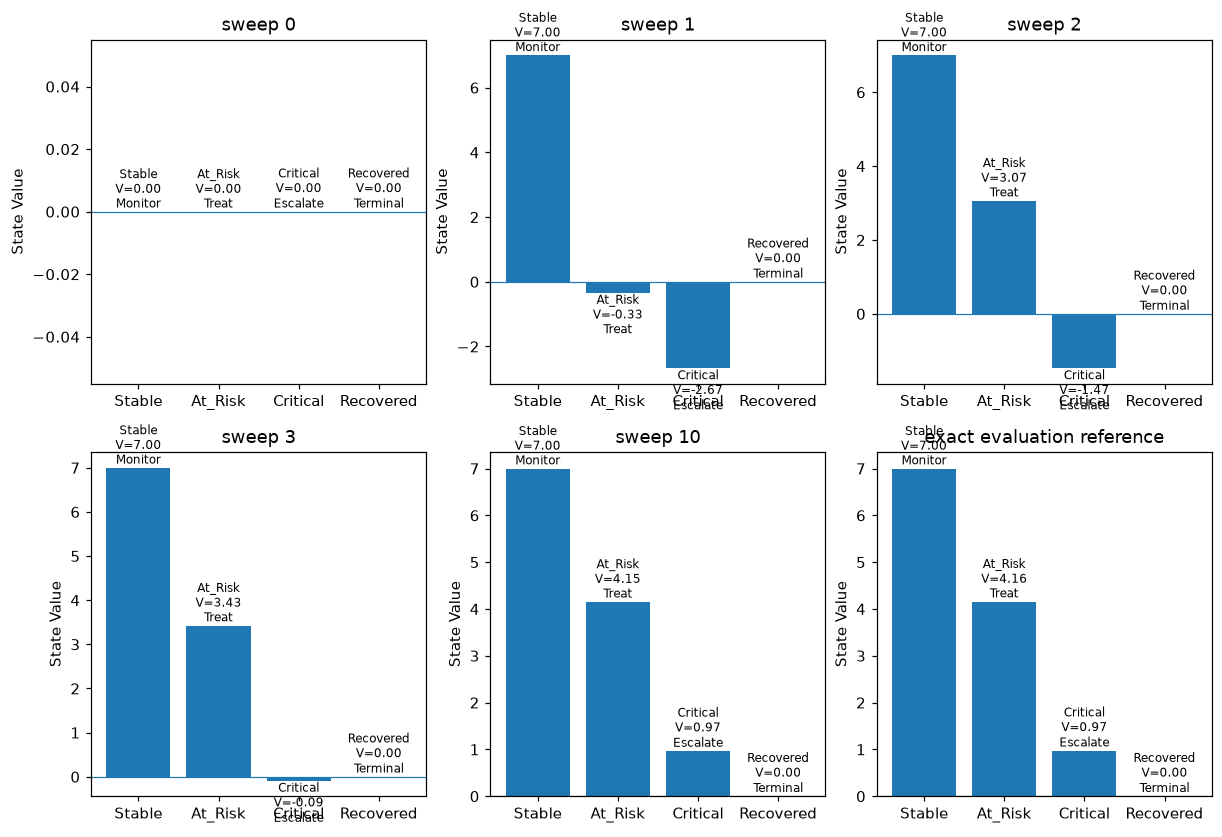

In [39]:
checkpoint_figure = new_figure(11.0, 7.5)

with Session(engine) as db:
    world = db.scalars(
        select(World).where(
            World.name == "Healthcare Patient Management"
        )
    ).one()

    run = find_run(
        db,
        world,
        "uniform iterative evaluation",
    )

    for panel, requested in enumerate(
        (0, 1, 2, 3, 10),
        start=1,
    ):
        sequence = min(
            requested,
            run.completed_sweeps,
        )

        snapshot = db.scalars(
            select(Snapshot).where(
                Snapshot.run_id == run.id,
                Snapshot.sequence == sequence,
            )
        ).one()

        greedify(db, run, snapshot)

        axis = checkpoint_figure.add_subplot(
            2,
            3,
            panel,
        )

        draw_snapshot(
            db,
            axis,
            snapshot,
            f"sweep {sequence}",
        )

    reference_run = find_run(
        db,
        world,
        "uniform exact evaluation",
    )

    reference = latest_snapshot(
        db,
        reference_run,
    )

    greedify(
        db,
        reference_run,
        reference,
    )

    draw_snapshot(
        db,
        checkpoint_figure.add_subplot(2, 3, 6),
        reference,
        "exact evaluation reference",
    )

    db.commit()

plt.show()

Healthcare MDP: 31 sweeps; error=1.778e-09


/var/folders/g5/g6p638rj2ygg_b0s4mvhw1bh0000gn/T/ipykernel_83978/2053279186.py:150: SADeprecationWarning: The Result.tuples() method is deprecated, Row now behaves like a tuple and can unpack types directly. (deprecated since: 2.1.0)
  in db.execute(statement).tuples()


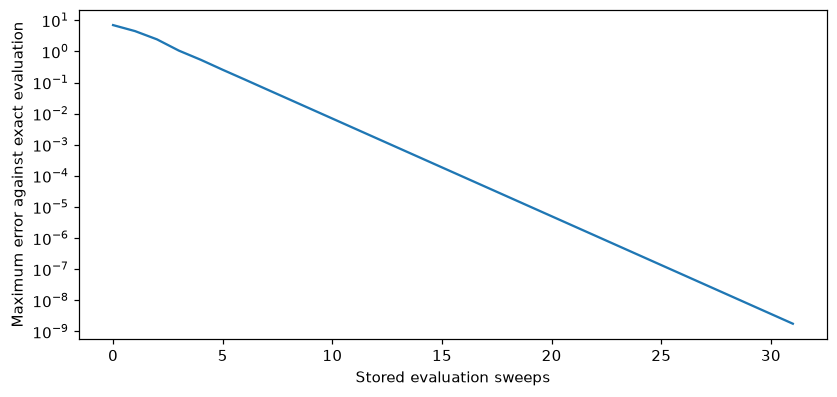

In [40]:
convergence_figure = new_figure(7.5, 3.5)
convergence_axis = convergence_figure.add_subplot(1, 1, 1)

with Session(engine) as db:
    world = db.scalars(
        select(World).where(
            World.name == "Healthcare Patient Management"
        )
    ).one()

    run = find_run(
        db,
        world,
        "uniform iterative evaluation",
    )

    curve = error_query(db, run)

    convergence_axis.plot(
        [x for x, _ in curve],
        [y for _, y in curve],
    )

    convergence_axis.set_yscale(
        "symlog",
        linthresh=1e-10,
    )

    convergence_axis.set_xlabel(
        "Stored evaluation sweeps"
    )

    convergence_axis.set_ylabel(
        "Maximum error against exact evaluation"
    )

    print(
        f"Healthcare MDP: "
        f"{run.completed_sweeps} sweeps; "
        f"error={curve[-1][1]:.3e}"
    )

plt.show()

## 5. Improvement and policy iteration

Policy improvement uses the action values from a policy-evaluation snapshot to construct a greedy policy. Policy iteration repeatedly evaluates the current policy and improves it until the policy no longer changes. In the healthcare MDP, this process converges when each nonterminal state keeps the same greedy action after another evaluation and improvement step.

In [41]:
def count_policy_changes(db: Session, old: Policy, new: Policy) -> int:
    previous = aliased(PolicyProbability)
    differences = (
        select(PolicyProbability.state_id)
        .join(previous, (
            (previous.state_id == PolicyProbability.state_id)
            & (previous.action_id == PolicyProbability.action_id)
        ))
        .where(PolicyProbability.policy_id == new.id, previous.policy_id == old.id)
        .where(func.abs(PolicyProbability.probability - previous.probability) > 1e-12)
        .group_by(PolicyProbability.state_id)
        .subquery()
    )
    return int(db.scalar(select(func.count()).select_from(differences)) or 0)


def policy_iteration(db: Session, run: Run) -> Snapshot:
    for iteration in range(1, run.max_iterations + 1):
        assert run.current_policy_id is not None
        policy = db.get(Policy, run.current_policy_id)
        assert policy is not None
        run.iterations = iteration
        snapshot = evaluate_exactly(db, run, policy)
        improved = greedify(db, run, snapshot)
        snapshot.changed_policy_states = count_policy_changes(db, policy, improved)
        run.current_policy_id = improved.id
        if snapshot.changed_policy_states == 0:
            assert snapshot.optimality_residual is not None
            if snapshot.optimality_residual > run.tolerance:
                raise RuntimeError("Policy is stable but its optimality residual is too large.")
            run.status = "converged"
            db.flush()
            return snapshot
    run.status = "failed"
    db.flush()
    raise RuntimeError("Policy iteration exceeded its stored iteration limit.")

In [42]:
with Session(engine) as db:
    world = db.scalars(
        select(World).where(
            World.name == "Healthcare Patient Management"
        )
    ).one()

    # Start from the evaluated uniform policy.
    evaluation_run = find_run(
        db,
        world,
        "uniform exact evaluation",
    )
    evaluation_snapshot = latest_snapshot(
        db,
        evaluation_run,
    )

    # One-step policy improvement.
    improved_policy = greedify(
        db,
        evaluation_run,
        evaluation_snapshot,
    )

    improvement_run = new_run(
        db,
        world,
        "one improvement",
        "policy_improvement",
        improved_policy,
    )

    improved_snapshot = evaluate_exactly(
        db,
        improvement_run,
        improved_policy,
    )

    greedify(
        db,
        improvement_run,
        improved_snapshot,
    )

    improvement_run.status = "converged"

    # Full policy iteration starting from the uniform policy.
    uniform = db.scalars(
        select(Policy).where(
            Policy.world_id == world.id,
            Policy.name == "uniform",
        )
    ).one()

    iteration_run = new_run(
        db,
        world,
        "policy iteration",
        "policy_iteration",
        uniform,
    )

    final_snapshot = policy_iteration(
        db,
        iteration_run,
    )

    db.commit()

    print(
        "Policy iteration status:",
        iteration_run.status,
    )
    print(
        "Policy iteration iterations:",
        iteration_run.iterations,
    )
    print(
        "Final snapshot:",
        final_snapshot.id,
    )

/var/folders/g5/g6p638rj2ygg_b0s4mvhw1bh0000gn/T/ipykernel_83978/1893586973.py:71: SADeprecationWarning: The Result.tuples() method is deprecated, Row now behaves like a tuple and can unpack types directly. (deprecated since: 2.1.0)
  for transition, probability in db.execute(statement).tuples():


Policy iteration status: converged
Policy iteration iterations: 2
Final snapshot: 69


In [43]:
with Session(engine) as db:
    world = db.scalars(
        select(World).where(
            World.name == "Healthcare Patient Management"
        )
    ).one()

    run = find_run(
        db,
        world,
        "policy iteration",
    )

    snapshot = latest_snapshot(db, run)

    assert snapshot.greedy_policy_id is not None

    states = db.scalars(
        select(State)
        .where(State.world_id == world.id)
        .order_by(State.ordinal)
    )

    print(f"{'State':<12}{'Action':<12}{'Probability':>12}")

    for state in states:
        rows = db.execute(
            select(
                Action.name,
                PolicyProbability.probability,
            )
            .join(
                PolicyProbability,
                PolicyProbability.action_id == Action.id,
            )
            .where(
                PolicyProbability.policy_id == snapshot.greedy_policy_id,
                PolicyProbability.state_id == state.id,
                PolicyProbability.probability > 0.0,
            )
            .order_by(Action.id)
        )

        for action_name, probability in rows:
            print(
                f"{state.name:<12}"
                f"{action_name:<12}"
                f"{probability:>12.3f}"
            )

State       Action       Probability
Stable      Monitor            1.000
At_Risk     Treat              1.000
Critical    Escalate           1.000
Recovered   Monitor            0.333
Recovered   Treat              0.333
Recovered   Escalate           0.333


**Look for:** how one greedy improvement changes the values of the initial uniform policy. The improved policy is evaluated before its values are plotted. The full policy-iteration run continues evaluating and improving the policy until no nonterminal state changes its greedy action and the optimality residual reaches the convergence tolerance.

Policy iteration: evaluated policies and changed state counts
0 3 9.327322404371584
1 0 0.0


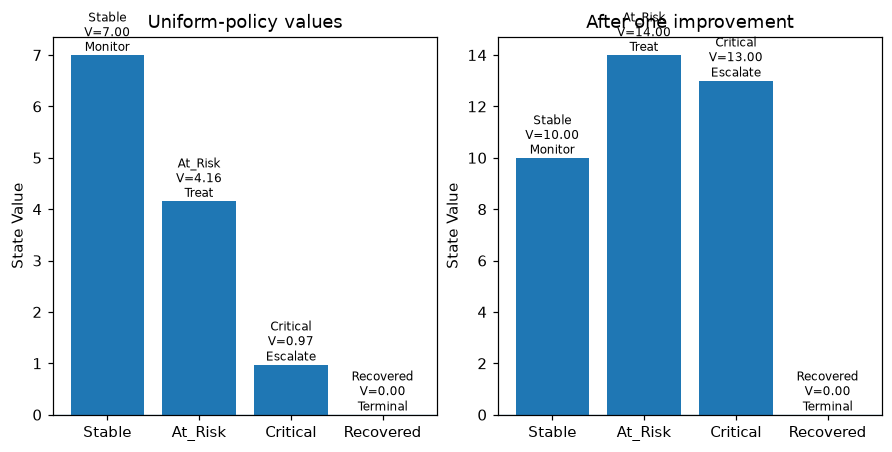

In [44]:
improvement_figure = new_figure(8.0, 4.0)

with Session(engine) as db:
    world = db.scalars(
        select(World).where(
            World.name == "Healthcare Patient Management"
        )
    ).one()

    # Values under the original uniform policy.
    before = latest_snapshot(
        db,
        find_run(
            db,
            world,
            "uniform exact evaluation",
        ),
    )

    # Values after one policy improvement.
    after = latest_snapshot(
        db,
        find_run(
            db,
            world,
            "one improvement",
        ),
    )

    draw_snapshot(
        db,
        improvement_figure.add_subplot(1, 2, 1),
        before,
        "Uniform-policy values",
    )

    draw_snapshot(
        db,
        improvement_figure.add_subplot(1, 2, 2),
        after,
        "After one improvement",
    )

    # Show how policy iteration progressed.
    run = find_run(
        db,
        world,
        "policy iteration",
    )

    print(
        "Policy iteration: evaluated policies "
        "and changed state counts"
    )

    for snapshot in db.scalars(
        select(Snapshot)
        .where(Snapshot.run_id == run.id)
        .order_by(Snapshot.sequence)
    ):
        print(
            snapshot.sequence,
            snapshot.changed_policy_states,
            snapshot.optimality_residual,
        )

plt.show()